In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

In [4]:
df = pd.read_csv(url, sep=";")

In [5]:
print(df.shape)

(1599, 12)


In [6]:
display(df.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [7]:
display(df["quality"].describe())

count    1599.000000
mean        5.636023
std         0.807569
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64

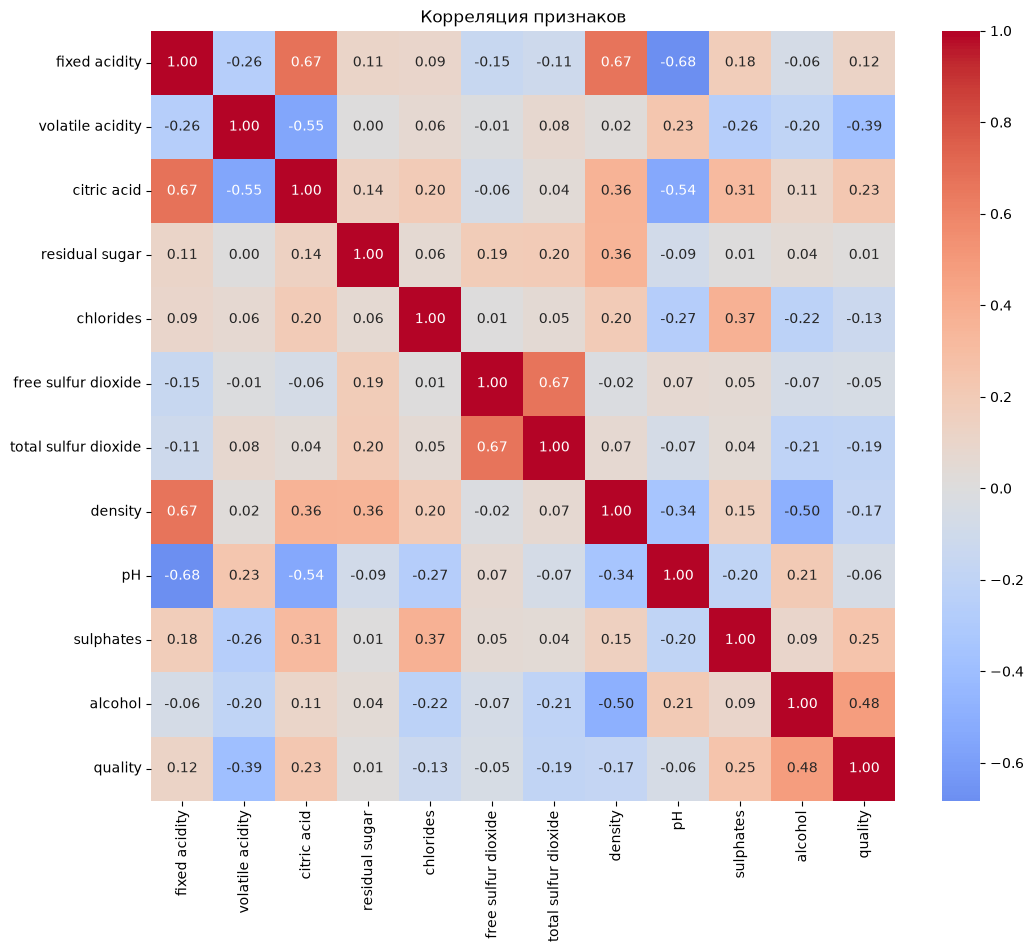

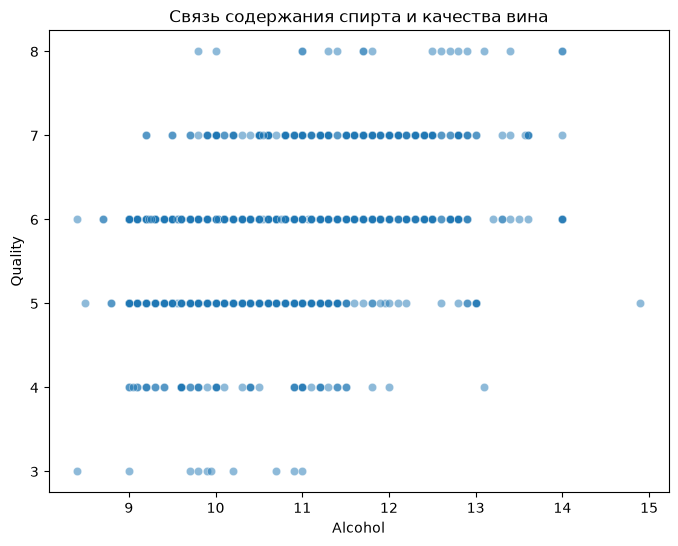

In [8]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", center=0)
plt.title("Корреляция признаков")
plt.show()

plt.figure(figsize=(8, 6))
sns.scatterplot(x=df['alcohol'], y=df['quality'], alpha=0.5)
plt.title("Связь содержания спирта и качества вина")
plt.xlabel("Alcohol")
plt.ylabel("Quality")
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["quality"])
y = df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

Размер обучающей выборки: (1279, 11)
Размер тестовой выборки: (320, 11)


In [11]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

pred_base = baseline.predict(X_test)

print("Baseline RMSE:", round(rmse(y_test, pred_base), 4))
print("Baseline MAE:", round(mean_absolute_error(y_test, pred_base), 4))

Baseline RMSE: 0.8107
Baseline MAE: 0.6853


In [12]:
from sklearn.linear_model import LinearRegression

linreg = LinearRegression()
linreg.fit(X_train, y_train)

pred_train = linreg.predict(X_train)
pred_test = linreg.predict(X_test)

print("Train RMSE:", round(rmse(y_train, pred_train), 4))
print("Test RMSE:", round(rmse(y_test, pred_test), 4))
print("Test MAE:", round(mean_absolute_error(y_test, pred_test), 4))

Train RMSE: 0.6513
Test RMSE: 0.6245
Test MAE: 0.5035


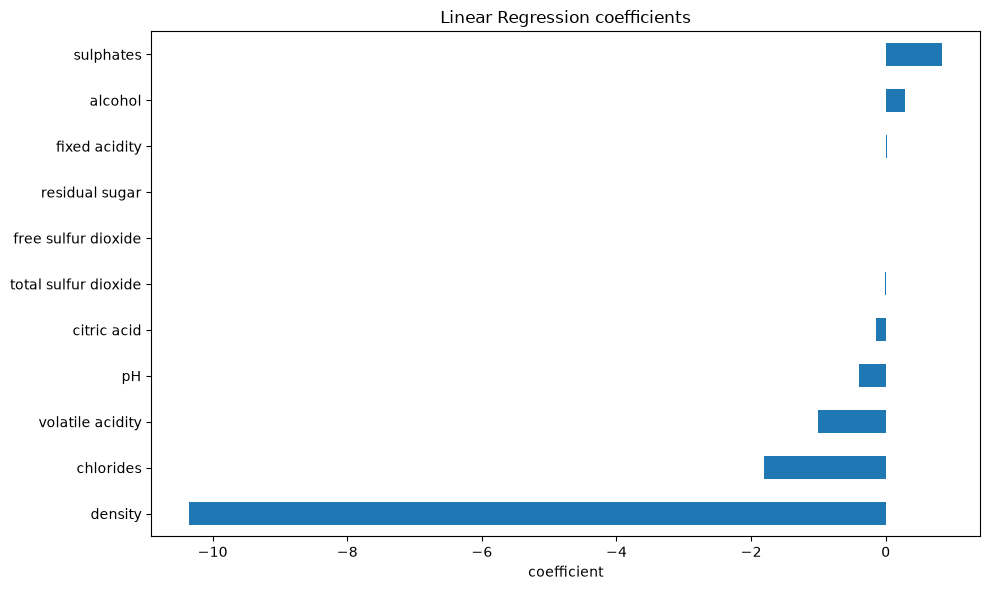

In [13]:
coef = pd.Series(linreg.coef_, index=X.columns)
coef = coef.sort_values()

ax = coef.plot(kind="barh", figsize=(10, 6))
ax.set_title("Linear Regression coefficients")
ax.set_xlabel("coefficient")
plt.tight_layout()
plt.show()

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso

ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(alpha=0.01, max_iter=10000))
])

for name, model in {"Ridge": ridge, "Lasso": lasso}.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"{name} RMSE:", round(rmse(y_test, pred), 4))

Ridge RMSE: 0.6245
Lasso RMSE: 0.6269


In [15]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

pred_rf_train = rf.predict(X_train)
pred_rf_test = rf.predict(X_test)

print("Random Forest Train RMSE:", round(rmse(y_train, pred_rf_train), 4))
print("Random Forest Test RMSE:", round(rmse(y_test, pred_rf_test), 4))
print("Random Forest Test MAE:", round(mean_absolute_error(y_test, pred_rf_test), 4))

Random Forest Train RMSE: 0.2186
Random Forest Test RMSE: 0.5489
Random Forest Test MAE: 0.4224


In [16]:
from sklearn.ensemble import GradientBoostingRegressor

gb = GradientBoostingRegressor(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)

pred_gb_train = gb.predict(X_train)
pred_gb_test = gb.predict(X_test)

print("Gradient Boosting Train RMSE:", round(rmse(y_train, pred_gb_train), 4))
print("Gradient Boosting Test RMSE:", round(rmse(y_test, pred_gb_test), 4))
print("Gradient Boosting Test MAE:", round(mean_absolute_error(y_test, pred_gb_test), 4))

Gradient Boosting Train RMSE: 0.499
Gradient Boosting Test RMSE: 0.6019
Gradient Boosting Test MAE: 0.4849


In [17]:
models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "Model": name,
        "RMSE": round(rmse(y_test, pred), 4),
        "MAE": round(mean_absolute_error(y_test, pred), 4),
    })

results = pd.DataFrame(rows).sort_values("RMSE")
display(results)

,Model,RMSE,MAE
2,Random Forest,0.5489,0.4224
3,Gradient Boosting,0.6019,0.4849
1,Linear Regression,0.6245,0.5035
0,Baseline,0.8107,0.6853


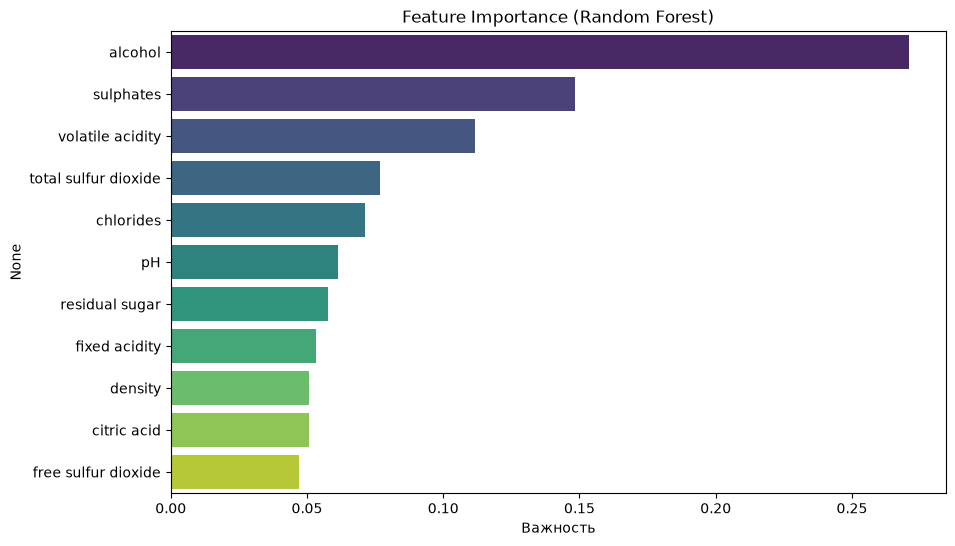

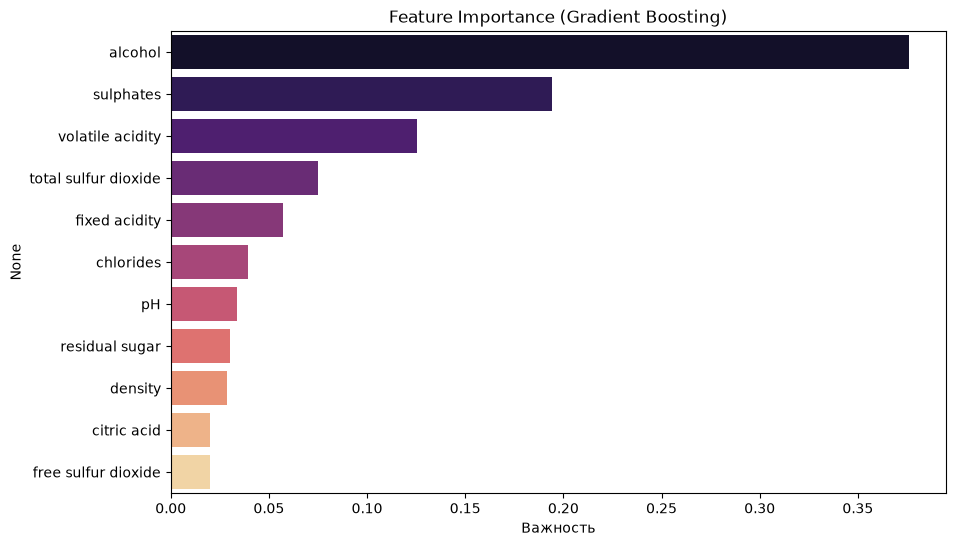

In [20]:
importances_rf = pd.Series(rf.feature_importances_, index=X.columns)
importances_rf = importances_rf.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances_rf, y=importances_rf.index, hue=importances_rf.index, palette='viridis', legend=False)
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Важность")
plt.show()

importances_gb = pd.Series(gb.feature_importances_, index=X.columns)
importances_gb = importances_gb.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances_gb, y=importances_gb.index, hue=importances_gb.index, palette='magma', legend=False)
plt.title("Feature Importance (Gradient Boosting)")
plt.xlabel("Важность")
plt.show()

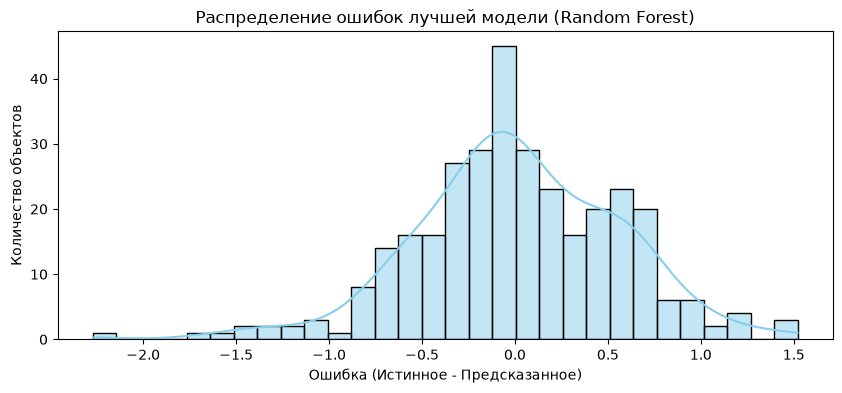

Объекты с наибольшими ошибками предсказания:


,True_Quality,Predicted_Quality,Absolute_Error
1505,3,5.27,2.27
1484,4,5.70,1.70
353,5,6.56,1.56
588,8,6.48,1.52
1449,8,6.49,1.51


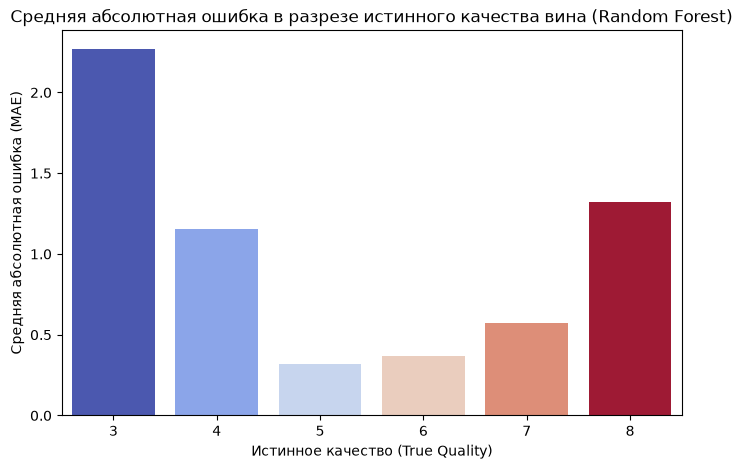

In [22]:
best_model = rf
pred_best = pred_rf_test

errors = y_test - pred_best

plt.figure(figsize=(10, 4))
sns.histplot(errors, bins=30, kde=True, color='skyblue')
plt.title("Распределение ошибок лучшей модели (Random Forest)")
plt.xlabel("Ошибка (Истинное - Предсказанное)")
plt.ylabel("Количество объектов")
plt.show()

test_results = pd.DataFrame({
    'True_Quality': y_test.values,
    'Predicted_Quality': pred_best,
    'Absolute_Error': np.abs(errors)
})
worst_predictions = test_results.sort_values(by='Absolute_Error', ascending=False).head(5)
print("Объекты с наибольшими ошибками предсказания:")
display(worst_predictions)

grouped_errors = test_results.groupby('True_Quality')['Absolute_Error'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    x='True_Quality', 
    y='Absolute_Error', 
    data=grouped_errors, 
    hue='True_Quality', 
    palette='coolwarm', 
    legend=False
)
plt.title("Средняя абсолютная ошибка в разрезе истинного качества вина (Random Forest)")
plt.xlabel("Истинное качество (True Quality)")
plt.ylabel("Средняя абсолютная ошибка (MAE)")
plt.show()